# F1 : Risque de crédit en Allemagne
**Nom et prénom :** Mouhib Chaimaa **Code Apogée :** 23003583 **Groupe :** FIN3
**Filière :** S7 FIN **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/mouhibchaimaa9355encg-arch/23003583_MOUHIB_CHAIMAA_G3.git

## 1. Sujet et problématique
- **Intérêt du sujet** : une banque doit décider d'accorder ou non un crédit. Accorder un crédit à un mauvais payeur coûte beaucoup plus cher que refuser un bon client. Le résultat sert à un analyste crédit pour fixer la règle d'acceptation.
- **Problématique** : parmi les demandeurs de crédit du jeu German Credit, peut-on repérer les mauvais payeurs de façon à réduire le coût moyen de décision par rapport à une règle naïve ?
- **Objectif mesurable** : coût moyen par dossier sur le test (FN = 5, FP = 1) inférieur d'au moins 20 % à celui de la référence « tout accorder ». Seuil fixé avant de voir les résultats du test.
- **Nature du problème** : classification binaire à coûts asymétriques (cible à deux classes : bon ou mauvais payeur).
- **Algorithme principal** : n°8, régression logistique.

configuration

In [81]:
df = pd.read_csv(RAW / "german_credit.csv")      # fichier placé dans data/raw/
df["cible"] = (df["risque"] == 2).astype(int)    # 1 = mauvais payeur
df = df.drop(columns="risque")
num_cols = ["duree_mois","montant","taux_mensualite","anciennete_residence","age","nb_credits","nb_personnes_charge"]
cat_cols = [c for c in df.columns if c not in num_cols + ["cible"]]

In [82]:
from google.colab import files
import shutil
from pathlib import Path

RAW = Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)

if not (RAW / "german_credit.csv").exists():
    envoye = files.upload()                      # une fenêtre s'ouvre : choisis german_credit.csv
    for nom in envoye:
        shutil.move(nom, RAW / "german_credit.csv")

print((RAW / "german_credit.csv").exists())      # doit afficher True

True


In [83]:
# Configuration : imports, graine, chemins relatifs, versions
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

GRAINE = 42
np.random.seed(GRAINE)

# Chemins relatifs à la racine du dépôt (aucun chemin absolu)
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = RACINE / "data" / "raw"
DATA_PROCESSED = RACINE / "data" / "processed"
FIGURES = RACINE / "figures"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)

print("Python        :", platform.python_version())
print("numpy         :", np.__version__)
print("pandas        :", pd.__version__)
print("matplotlib    :", matplotlib.__version__)
print("scikit-learn  :", sklearn.__version__)

Python        : 3.13.18
numpy         : 2.4.6
pandas        : 2.2.3
matplotlib    : 3.10.0
scikit-learn  : 1.6.1


## 2. Jeu de données
- **Nom et source** : German Credit Data (Statlog), UCI Machine Learning Repository, https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data. Fichier utilisé : version CSV `german_credit.csv`. **Date d'extraction :** 17/11/2026 (à corriger si tu l'as téléchargé un autre jour).
- **Licence** : [à vérifier sur la page UCI du jeu ; si rien n'est indiqué, écrire « aucune condition indiquée »].
- **Taille** : 1000 observations, 21 colonnes (20 explicatives et la cible). Pas de période ni de fréquence : ce sont des dossiers indépendants.
- **Unité d'observation** : une ligne = un dossier de demande de crédit.
- **Variable cible** : bon payeur (0) ou mauvais payeur (1), recodée à partir de la colonne `risque` (1 = bon, 2 = mauvais) pour que « 1 » désigne le défaut à détecter.
- **Adéquation** : la cible indique l'issue du crédit et les variables décrivent le client et le crédit, donc le jeu permet de répondre à la problématique.
- **Limites** : petit échantillon (1000 dossiers, soit 200 au test) ; classes déséquilibrées (700 bons payeurs contre 300 mauvais, soit 70 % / 30 %) ; jeu ancien et allemand, peu représentatif d'un portefeuille actuel ; variables catégorielles codées (A11, A12...) ; pas de dimension temporelle ; coûts 5 contre 1 supposés fixes.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| duree_mois | Durée du crédit | numérique | mois | explicative | 0 |
| montant | Montant du crédit | numérique | DM | explicative | 0 |
| age | Âge du demandeur | numérique | années | explicative | 0 |
| taux_mensualite | Taux de remboursement (% du revenu disponible) | numérique | % | explicative | 0 |
| statut_compte | Statut du compte courant | catégorielle | code | explicative | 0 |
| historique_credit | Historique de crédit | catégorielle | code | explicative | 0 |
| objet | Objet du crédit | catégorielle | code | explicative | 0 |
| cible | Mauvais payeur (1) ou bon payeur (0) | binaire | 0/1 | cible | 0 |

chargement et vérification

In [84]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
fichier = RAW / "german.data"
if not fichier.exists():
    urllib.request.urlretrieve(URL, fichier)
print("Date d'extraction :", date.today())

cols = ["statut_compte","duree","historique_credit","objet","montant","epargne",
        "anciennete_emploi","taux_remboursement","statut_personnel","autres_debiteurs",
        "anciennete_residence","bien","age","autres_plans","logement","nb_credits",
        "emploi","nb_personnes_charge","telephone","travailleur_etranger","cible"]
df = pd.read_csv(fichier, sep=r"\s+", header=None, names=cols)
df["cible"] = (df["cible"] == 2).astype(int)   # 1 = mauvais payeur, 0 = bon payeur

num_cols = ["duree","montant","taux_remboursement","anciennete_residence","age","nb_credits","nb_personnes_charge"]
cat_cols = [c for c in cols if c not in num_cols + ["cible"]]

print("Dimensions :", df.shape)
print(df.dtypes.value_counts())
print("Valeurs manquantes :", df.isna().sum().sum(), "| Doublons :", df.duplicated().sum())
print(df["cible"].value_counts(normalize=True).round(3))
df.head()

Date d'extraction : 2026-11-17
Dimensions : (1000, 21)
object    13
int64      8
Name: count, dtype: int64
Valeurs manquantes : 0 | Doublons : 0
cible
0    0.7
1    0.3
Name: proportion, dtype: float64


,statut_compte,duree,historique_credit,objet,montant,epargne,anciennete_emploi,taux_remboursement,statut_personnel,autres_debiteurs,...,bien,age,autres_plans,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,cible
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


dictionnaire vérifié

In [85]:
dico = pd.DataFrame({
    "Variable": ["duree","montant","age","taux_remboursement","statut_compte","historique_credit","objet","cible"],
    "Description": ["Durée du crédit","Montant du crédit","Âge du demandeur",
                    "Taux de remboursement (% du revenu disponible)","Statut du compte courant",
                    "Historique de crédit","Objet du crédit","Mauvais payeur (1) ou bon payeur (0)"],
    "Type": ["numérique"]*4 + ["catégorielle"]*3 + ["binaire"],
    "Unité": ["mois","DM","années","%","code","code","code","0/1"],
    "Rôle": ["explicative"]*7 + ["cible"],
})
dico["Manquants (%)"] = [df[v].isna().mean() * 100 for v in dico["Variable"]]
dico

,Variable,Description,Type,Unité,Rôle,Manquants (%)
0,duree,Durée du crédit,numérique,mois,explicative,0.0
1,montant,Montant du crédit,numérique,DM,explicative,0.0
2,age,Âge du demandeur,numérique,années,explicative,0.0
3,taux_remboursement,Taux de remboursement (% du revenu disponible),numérique,%,explicative,0.0
4,statut_compte,Statut du compte courant,catégorielle,code,explicative,0.0
5,historique_credit,Historique de crédit,catégorielle,code,explicative,0.0
6,objet,Objet du crédit,catégorielle,code,explicative,0.0
7,cible,Mauvais payeur (1) ou bon payeur (0),binaire,0/1,cible,0.0


## 3. Exploration
- **Qualité des données** : valeurs manquantes : 0 (méthode `isna().sum()`), rien à imputer. Doublons : 0 (méthode `duplicated().sum()`), rien à supprimer. Valeurs atypiques : 72 montants dépassent 7 882 DM (règle IQR : Q3 + 1,5 × écart interquartile) ; je les **conserve**, car ce sont de vrais gros crédits et non des erreurs.
- **Graphique 1 (répartition de la cible)** : 700 bons payeurs contre 300 mauvais payeurs. Les classes sont déséquilibrées, donc l'accuracy serait trompeuse (« tout accorder » aurait déjà 70 % de bonnes réponses) : j'utilise le coût moyen et le rappel, avec un découpage stratifié.
- **Graphique 2 (montant selon la cible)** : la médiane du montant des mauvais payeurs est un peu plus élevée que celle des bons payeurs (2 574 DM contre 2 244 DM), avec beaucoup de montants élevés dans les deux groupes. Le montant seul ne sépare pas bien les classes : il faut un modèle multivarié.
- **Graphique 3 (taux de mauvais payeurs selon le statut du compte)** : le taux va de 11,7 % (code A14) à 49,3 % (code A11). Cette variable est très informative, mais c'est une corrélation, pas une preuve de causalité.


STATISTIQUES


In [86]:
print(df[num_cols].describe().T.round(1))
q1, q3 = df["montant"].quantile([.25, .75]); iqr = q3 - q1
print("Montants atypiques (règle IQR) :", int((df["montant"] > q3 + 1.5 * iqr).sum()))

                       count    mean     std    min     25%     50%     75%  \
duree                 1000.0    20.9    12.1    4.0    12.0    18.0    24.0   
montant               1000.0  3271.3  2822.7  250.0  1365.5  2319.5  3972.2   
taux_remboursement    1000.0     3.0     1.1    1.0     2.0     3.0     4.0   
anciennete_residence  1000.0     2.8     1.1    1.0     2.0     3.0     4.0   
age                   1000.0    35.5    11.4   19.0    27.0    33.0    42.0   
nb_credits            1000.0     1.4     0.6    1.0     1.0     1.0     2.0   
nb_personnes_charge   1000.0     1.2     0.4    1.0     1.0     1.0     1.0   

                          max  
duree                    72.0  
montant               18424.0  
taux_remboursement        4.0  
anciennete_residence      4.0  
age                      75.0  
nb_credits                4.0  
nb_personnes_charge       2.0  
Montants atypiques (règle IQR) : 72


Cellules 8 à 10 : trois graphiques, chacun suivi de son interprétation

CODE 8:

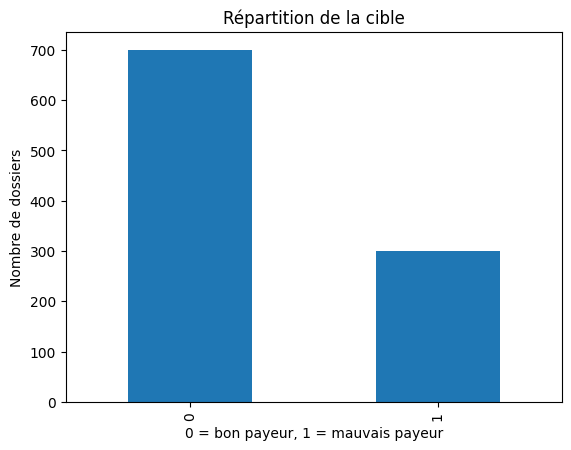

In [87]:
ax = df["cible"].value_counts().sort_index().plot.bar()
ax.set_title("Répartition de la cible")
ax.set_xlabel("0 = bon payeur, 1 = mauvais payeur"); ax.set_ylabel("Nombre de dossiers")
plt.savefig(FIG/"cible.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation du graphique 1.** Les classes sont déséquilibrées : 700 bons payeurs contre 300 mauvais payeurs (70 % / 30 %). Conséquence : l'accuracy serait trompeuse (une règle « tout accorder » aurait déjà 70 % de bonnes réponses), d'où le choix du coût moyen et du rappel des mauvais payeurs comme métriques, et d'un découpage stratifié.

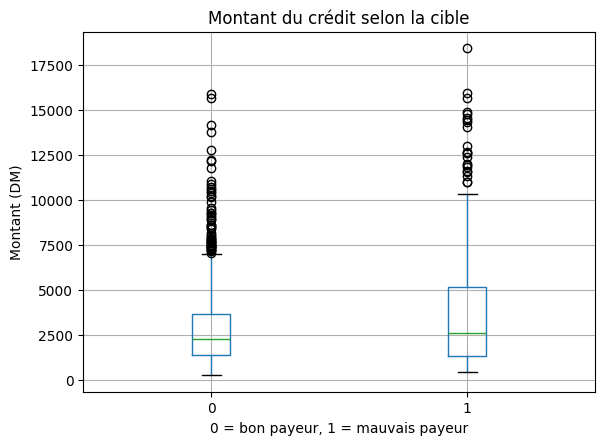

In [88]:
df.boxplot(column="montant", by="cible")
plt.suptitle(""); plt.title("Montant du crédit selon la cible")
plt.xlabel("0 = bon payeur, 1 = mauvais payeur"); plt.ylabel("Montant (DM)")
plt.savefig(FIG/"montant.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation du graphique 2.** La médiane du montant des mauvais payeurs est un peu plus élevée que celle des bons payeurs (2 574,5 DM contre 2 244 DM), mais les deux distributions se recouvrent largement et contiennent beaucoup de montants élevés. Le montant seul ne sépare donc pas bien les deux classes : il faut un modèle qui combine plusieurs variables.

statut_compte
A11    49.3
A12    39.0
A13    22.2
A14    11.7
Name: cible, dtype: float64


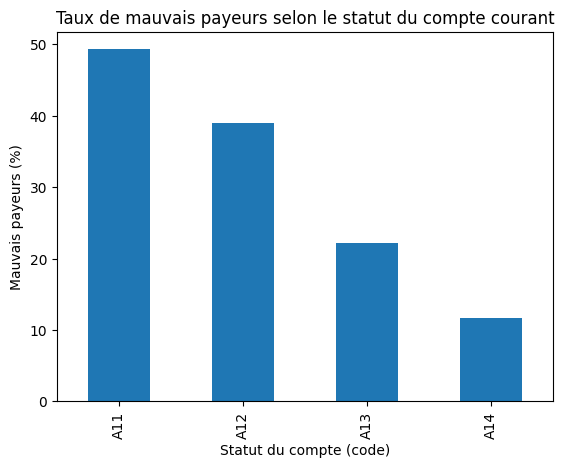

In [89]:
taux = df.groupby("statut_compte")["cible"].mean().mul(100)
print(taux.round(1))
ax = taux.plot.bar()
ax.set_title("Taux de mauvais payeurs selon le statut du compte courant")
ax.set_xlabel("Statut du compte (code)"); ax.set_ylabel("Mauvais payeurs (%)")
plt.savefig(FIG/"statut_compte.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation du graphique 3.** Le taux de mauvais payeurs va de 11,7 % (code A14) à 49,3 % (code A11), en passant par 39,0 % (A12) et 22,2 % (A13). Le statut du compte courant est donc très lié au risque et sera probablement une variable importante. Attention : c'est une corrélation observée dans ces données, pas une preuve de causalité.

## 4. Préparation
- **Découpage** : 80 % apprentissage (800 dossiers) / 20 % test (200 dossiers), **stratifié** (30 % de mauvais payeurs dans les deux jeux), fait **avant** toute transformation. Il n'y a pas de dimension temporelle, donc pas de découpage chronologique.
- **Encodage** : one-hot pour les variables catégorielles (le modèle ne peut pas utiliser directement des codes comme « A11 ). Les catégories inconnues au test sont ignorées.
- **Mise à l'échelle** : standardisation des variables numériques, **nécessaire ici** car la régression logistique est régularisée (pénalité L2) et sensible à l'échelle (le montant, en milliers de DM, écraserait sinon l'âge ou la durée).
- **Prévention des fuites** : encodage et standardisation sont dans un `Pipeline`, donc ajustés (fit) sur l'apprentissage seulement et réajustés dans chaque pli de validation croisée. Le test n'est utilisé qu'une fois, à la fin. Aucune variable explicative ne contient la cible. Aucune variable n'est créée.

In [90]:
X, y = df.drop(columns="cible"), df["cible"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=GRAINE)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Part de mauvais payeurs - train :", y_train.mean().round(3), "| test :", y_test.mean().round(3))

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

# Une ligne après préparation (transformation ajustée sur le train seulement)
ligne = pd.DataFrame(prep.fit_transform(X_train)[:1], columns=prep.get_feature_names_out())
ligne.iloc[:, :10]

Train : (800, 20) | Test : (200, 20)
Part de mauvais payeurs - train : 0.3 | test : 0.3


,num__duree,num__montant,num__taux_remboursement,num__anciennete_residence,num__age,num__nb_credits,num__nb_personnes_charge,cat__statut_compte_A11,cat__statut_compte_A12,cat__statut_compte_A13
0,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,1.0,0.0,0.0


## 5. Algorithme : régression logistique (n°8)
**Intuition.** Le modèle combine les caractéristiques du client en un score, puis transforme ce score en probabilité de défaut.

**Formule :**  P(y = 1 | x) = 1 / (1 + exp(−(β0 + β1·x1 + … + βp·xp)))

où y = 1 désigne un mauvais payeur ; x1…xp sont les caractéristiques du client (montant, durée, âge, etc.) ; β0 est la constante ; β1…βp sont les coefficients ; exp est l'exponentielle, qui ramène le score entre 0 et 1.

**Apprentissage.** Les coefficients β sont **appris** en minimisant la perte logistique (log-vraisemblance négative) avec une pénalité L2 qui limite leur taille. Les **hyperparamètres**, fixés par moi, sont C et le seuil de décision.

**Schéma.** Données → découpage train/test → encodage + standardisation (fit sur train) → score β·x → probabilité de défaut → comparaison au seuil → décision (accorder ou refuser).

**Hyperparamètres.**
- **C** : inverse de la force de régularisation. Un petit C donne un modèle plus simple (coefficients plus petits, moins de surapprentissage) ; un grand C donne un modèle plus flexible.
- **Seuil** : on refuse le crédit si la probabilité de défaut dépasse le seuil ; un seuil plus bas refuse plus de dossiers. Avec des coûts 5 (mauvais accepté) et 1 (bon refusé), le seuil théorique est 1/(5+1) ≈ 0,17.

**Pourquoi cet algorithme.** Problème de classification binaire, petit échantillon (1000 lignes), besoin d'interpréter les coefficients, et besoin d'une probabilité pour régler le seuil selon les coûts. **Alternative écartée** : KNN (n°9), sensible à l'échelle des variables, peu interprétable et dont les probabilités sont grossières avec peu de données.

**Contextes d'usage.** Scoring de crédit, détection de fraude, prévision de défaut d'entreprise.

## 6. Protocole expérimental
- **Découpage** : 80 % / 20 %, stratifié, graine 42 (données non datées, donc pas d'ordre chronologique). Le test n'est utilisé qu'**une seule fois**, à la fin.
- **Référence naïve** : tout classer « bon payeur » (tout accorder), sans aucun apprentissage.
- **Réglage** : `GridSearchCV` avec `StratifiedKFold` à 5 plis, sur l'apprentissage seulement, C ∈ {0,01 ; 0,1 ; 1 ; 10 ; 100}, soit **5 configurations essayées**. Score de sélection : AUC. Meilleur C : 0,1 (AUC de validation 0,784).
- **Seuil** : choisi sur les probabilités hors-pli du train (`cross_val_predict`), en minimisant le coût moyen, jamais sur le test. Seuil retenu : 0,18.
- **Métrique principale** : coût moyen par dossier = (5 × FN + 1 × FP) / n, où FN = mauvais payeur accepté et FP = bon client refusé. Elle est exprimée en unités de coût par dossier et reflète l'asymétrie réelle. **Secondaires** : rappel des mauvais payeurs (part des défauts détectés) et AUC (qualité du classement, indépendante du seuil). L'accuracy est écartée, car trompeuse avec des classes déséquilibrées.
- **Incertitude** : coût de validation = 0,512 ± 0,063 (moyenne et écart-type sur les 5 plis).

In [72]:
COUT_FN, COUT_FP = 5, 1
def cout_moyen(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    fn = ((y_true == 1) & (y_pred == 0)).sum()
    fp = ((y_true == 0) & (y_pred == 1)).sum()
    return (COUT_FN * fn + COUT_FP * fp) / len(y_true)

pipe = Pipeline([("prep", prep),
                 ("clf", LogisticRegression(max_iter=1000, random_state=GRAINE))])
cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE)
grille = {"clf__C": [0.01, 0.1, 1, 10, 100]}
gs = GridSearchCV(pipe, grille, scoring="roc_auc", cv=cv, return_train_score=True).fit(X_train, y_train)
modele = gs.best_estimator_
print("Configurations essayées :", len(grille["clf__C"]))
print("Meilleur C :", gs.best_params_, "| AUC validation :", round(gs.best_score_, 3))

# Choix du seuil sur le train uniquement (probabilités hors-pli)
proba_oof = cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
seuils = np.arange(0.05, 0.96, 0.01)
couts = [cout_moyen(y_train, proba_oof >= t) for t in seuils]
seuil_opt = seuils[int(np.argmin(couts))]
print("Seuil optimal :", round(seuil_opt, 2), "| seuil théorique 1/6 :", round(1/6, 2))

# Incertitude : coût par pli de validation
couts_plis = [cout_moyen(y_train.iloc[v], proba_oof[v] >= seuil_opt) for _, v in cv.split(X_train, y_train)]
print("Coût validation : moyenne", round(np.mean(couts_plis), 3), "| écart-type", round(np.std(couts_plis), 3))

Configurations essayées : 5
Meilleur C : {'clf__C': 0.1} | AUC validation : 0.784
Seuil optimal : 0.18 | seuil théorique 1/6 : 0.17
Coût validation : moyenne 0.512 | écart-type 0.063


## 7. Résultats

In [73]:
proba_test = modele.predict_proba(X_test)[:, 1]
zeros_tr, zeros_te = np.zeros(len(y_train)), np.zeros(len(y_test))

res = pd.DataFrame({
    "Référence (tout accorder)": [cout_moyen(y_train, zeros_tr), cout_moyen(y_test, zeros_te), 0.0, 0.5],
    "Modèle, seuil 0,5": [cout_moyen(y_train, proba_oof >= 0.5), cout_moyen(y_test, proba_test >= 0.5),
                          recall_score(y_test, proba_test >= 0.5), roc_auc_score(y_test, proba_test)],
    "Modèle, seuil optimal": [np.mean(couts_plis), cout_moyen(y_test, proba_test >= seuil_opt),
                              recall_score(y_test, proba_test >= seuil_opt), roc_auc_score(y_test, proba_test)],
}, index=["Coût moyen (validation)", "Coût moyen (test)",
          "Rappel mauvais payeurs (test)", "AUC (test)"]).round(3)
res.to_csv(PROC / "resultats.csv")
display(res)

reduction = 1 - cout_moyen(y_test, proba_test >= seuil_opt) / cout_moyen(y_test, zeros_te)
print("Réduction du coût vs référence :", round(100 * reduction, 1), "%")
print("Objectif (>= 20 %) atteint :", bool(reduction >= 0.20))

,Référence (tout accorder),"Modèle, seuil 0,5","Modèle, seuil optimal"
Coût moyen (validation),1.5,0.978,0.512
Coût moyen (test),1.5,0.810,0.535
Rappel mauvais payeurs (test),0.0,0.500,0.883
AUC (test),0.5,0.810,0.810


Réduction du coût vs référence : 64.3 %
Objectif (>= 20 %) atteint : True


**Interprétation du tableau.** Sur le test, la référence « tout accorder » coûte 1,500 par dossier. Le modèle au seuil 0,5 coûte 0,810 et, au seuil optimal (0,18), il coûte 0,535, soit une réduction de 64,3 % par rapport à la référence : l'objectif de 20 % est atteint. Le rappel des mauvais payeurs passe de 0 (la référence n'en détecte aucun) à 0,500 au seuil 0,5 puis à 0,883 au seuil optimal. Le seuil optimal est plus bas que 0,5 parce qu'un mauvais payeur accepté coûte 5 fois plus qu'un bon client refusé : il vaut mieux refuser davantage de dossiers. En contrepartie, beaucoup de bons clients sont refusés (voir la matrice de confusion).

AUC apprentissage : [0.806 0.831 0.84  0.842 0.842] | validation : [0.775 0.784 0.771 0.76  0.756]


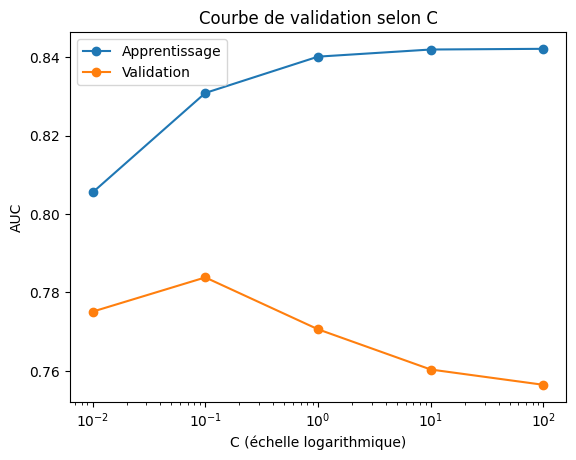

In [74]:
r = gs.cv_results_; Cs = grille["clf__C"]
print("AUC apprentissage :", r["mean_train_score"].round(3), "| validation :", r["mean_test_score"].round(3))
plt.semilogx(Cs, r["mean_train_score"], marker="o", label="Apprentissage")
plt.semilogx(Cs, r["mean_test_score"], marker="o", label="Validation")
plt.xlabel("C (échelle logarithmique)"); plt.ylabel("AUC")
plt.title("Courbe de validation selon C"); plt.legend()
plt.savefig(FIG/"validation_C.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation de la courbe de validation.** L'AUC d'apprentissage augmente avec C (de 0,806 à 0,842) alors que l'AUC de validation est maximale pour C = 0,1 (0,784) puis baisse (0,756 pour C = 100). L'écart entre apprentissage et validation grandit donc quand le modèle devient plus flexible : c'est du surapprentissage. Le C retenu (0,1) est celui qui maximise l'AUC de validation.

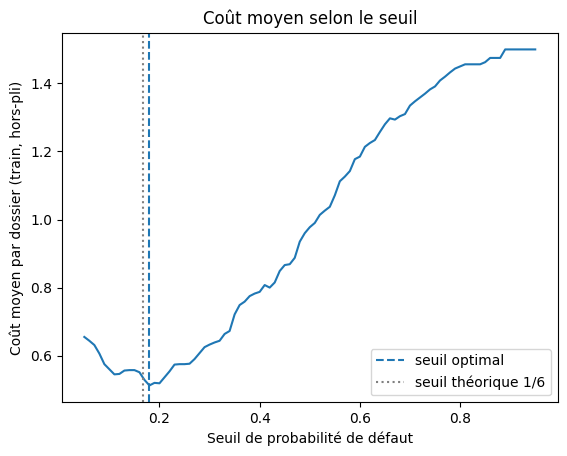

In [75]:
plt.plot(seuils, couts)
plt.axvline(seuil_opt, ls="--", label="seuil optimal")
plt.axvline(1/6, ls=":", color="gray", label="seuil théorique 1/6")
plt.xlabel("Seuil de probabilité de défaut"); plt.ylabel("Coût moyen par dossier (train, hors-pli)")
plt.title("Coût moyen selon le seuil"); plt.legend()
plt.savefig(FIG/"cout_seuil.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation de la courbe du seuil.** Le coût est minimal (0,512) pour un seuil de 0,18, très proche du seuil théorique 1/6 ≈ 0,17. Au seuil habituel de 0,5, le coût hors-pli du train monte à 0,978. À seuil très bas on refuse presque tout (beaucoup de bons clients refusés) ; à seuil élevé on accorde presque tout et le coût se rapproche de celui de la référence. Le choix du seuil compte donc autant que le choix du modèle.

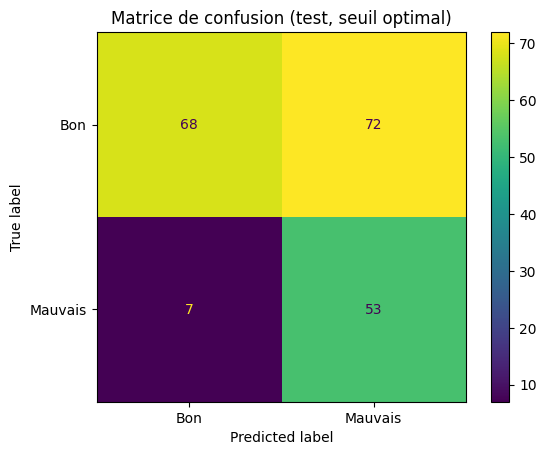

cas
FP    72
VN    68
VP    53
FN     7
Name: count, dtype: int64
     montant  duree   age
cas                      
FN    3073.9   15.0  35.9
FP    3965.3   22.8  37.1
VN    2265.9   15.7  39.3
VP    4877.1   27.8  32.0


,duree,montant,age,statut_compte,proba
190,24,4591,54,A14,0.065
435,12,1484,25,A12,0.081
228,9,1478,22,A14,0.097
796,18,7511,51,A11,0.118
647,12,1386,26,A14,0.122


In [76]:
pred_test = (proba_test >= seuil_opt).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Bon", "Mauvais"]).plot()
plt.title("Matrice de confusion (test, seuil optimal)")
plt.savefig(FIG/"confusion.png", dpi=150, bbox_inches="tight"); plt.show()

err = X_test.copy()
err["proba"] = proba_test; err["reel"] = y_test.values; err["pred"] = pred_test
err["cas"] = np.select([(err.reel == 1) & (err.pred == 1),
                        (err.reel == 1) & (err.pred == 0),
                        (err.reel == 0) & (err.pred == 1)], ["VP", "FN", "FP"], "VN")
print(err["cas"].value_counts())
print(err.groupby("cas")[["montant", "duree", "age"]].mean().round(1))
err[err.cas == "FN"].sort_values("proba").head(5)[["duree", "montant", "age", "statut_compte", "proba"]].round(3)

**Analyse des erreurs.** Sur les 60 mauvais payeurs du test, le modèle en détecte 53 (VP) et en laisse passer 7 (FN), qui coûtent 5 chacun (7 × 5 = 35). Il refuse aussi 72 bons clients sur 140 (FP, coût 1 chacun, soit 72) : c'est le prix d'un seuil bas. Les faux négatifs sont des crédits plus petits et plus courts (montant moyen 3 074 DM, durée moyenne 15 mois) que les mauvais payeurs détectés (4 877 DM, 27,8 mois) : le modèle repère surtout les gros crédits longs et rate les petits défauts. Les cas les plus mal classés ont une probabilité de défaut entre 0,065 et 0,122 alors qu'ils ont fait défaut ; par exemple le dossier 190 (24 mois, 4 591 DM, 54 ans, compte A14, probabilité 0,065), dont le statut de compte A14 est associé au risque le plus faible.

cat__statut_compte_A14       -0.72
cat__statut_compte_A11        0.53
cat__historique_credit_A34   -0.53
cat__epargne_A61              0.46
cat__objet_A41               -0.42
cat__objet_A46                0.38
cat__statut_personnel_A93    -0.34
cat__anciennete_emploi_A74   -0.34
cat__epargne_A65             -0.34
cat__objet_A40                0.32
dtype: float64
statut_compte         0.101
duree                 0.029
historique_credit     0.028
objet                 0.027
montant               0.021
taux_remboursement    0.019
autres_debiteurs      0.006
age                   0.005
dtype: float64


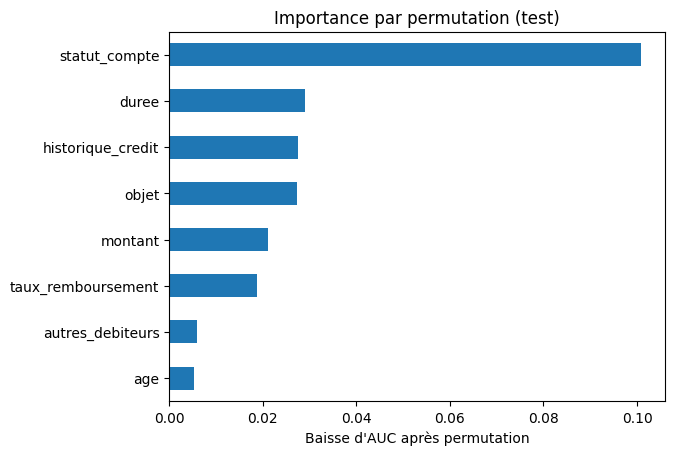

In [77]:
noms = modele.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modele.named_steps["clf"].coef_[0], index=noms)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(2))

pi = permutation_importance(modele, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=GRAINE)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(8)
print(imp.sort_values(ascending=False).round(3))
imp.plot.barh()
plt.xlabel("Baisse d'AUC après permutation"); plt.title("Importance par permutation (test)")
plt.savefig(FIG/"importance.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation prudente des variables.** Les coefficients les plus forts sont `statut_compte_A14` (−0,72, diminue la probabilité de défaut), `statut_compte_A11` (+0,53, l'augmente), `historique_credit_A34` (−0,53) et `epargne_A61` (+0,46), les autres variables étant fixées. L'importance par permutation confirme que le statut du compte courant domine (baisse d'AUC de 0,101), loin devant la durée (0,029) et l'historique de crédit (0,028). Ces résultats décrivent des associations dans ces données, pas des relations de cause à effet.

In [78]:
cout_train = cout_moyen(y_train, modele.predict_proba(X_train)[:, 1] >= seuil_opt)
print("Coût train :", round(cout_train, 3), "| coût test :", round(cout_moyen(y_test, pred_test), 3))

def procedure(graine):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=graine)
    cv_ = StratifiedKFold(5, shuffle=True, random_state=graine)
    g = GridSearchCV(clone(pipe), grille, scoring="roc_auc", cv=cv_).fit(Xtr, ytr)
    oof = cross_val_predict(g.best_estimator_, Xtr, ytr, cv=cv_, method="predict_proba")[:, 1]
    s = seuils[int(np.argmin([cout_moyen(ytr, oof >= t) for t in seuils]))]
    p = g.best_estimator_.predict_proba(Xte)[:, 1]
    return s, cout_moyen(yte, p >= s), cout_moyen(yte, np.zeros(len(yte)))

stab = pd.DataFrame([procedure(g) for g in [1, 2, 3, 4, 5]],
                    columns=["seuil", "coût modèle", "coût référence"], index=[1, 2, 3, 4, 5]).round(3)
stab.index.name = "graine"
display(stab)

Coût train : 0.466 | coût test : 0.535


,seuil,coût modèle,coût référence
graine,,,
1,0.14,0.510,1.5
2,0.17,0.520,1.5
3,0.19,0.520,1.5
4,0.14,0.585,1.5
5,0.22,0.570,1.5


**Généralisation.** Le coût au train (0,466) est un peu plus faible que celui du test (0,535) : le modèle surapprend légèrement, ce qui est cohérent avec la courbe de validation. Pour tester la stabilité, j'ai relancé toute la procédure avec 5 autres découpages (analyse de robustesse séparée : le test principal n'a servi qu'une fois). Le modèle bat la référence dans 5 cas sur 5 : son coût varie de 0,510 à 0,585 contre 1,500 pour la référence, avec un seuil compris entre 0,14 et 0,22. Le résultat est donc stable sur ce point, mais l'écart de coût d'un découpage à l'autre rappelle que 200 dossiers de test restent peu.

In [79]:
ex = X_test.sample(5, random_state=GRAINE)[["duree", "montant", "age", "statut_compte"]].copy()
ex["proba_défaut"] = modele.predict_proba(X_test.loc[ex.index])[:, 1].round(2)
ex["décision"] = np.where(ex["proba_défaut"] >= seuil_opt, "Refuser", "Accorder")
ex["réel"] = y_test.loc[ex.index].map({0: "bon payeur", 1: "mauvais payeur"})
ex

,duree,montant,age,statut_compte,proba_défaut,décision,réel
662,21,2241,50,A14,0.17,Accorder,bon payeur
430,5,3448,74,A14,0.04,Accorder,bon payeur
551,6,1750,45,A14,0.10,Accorder,bon payeur
263,12,2748,57,A14,0.30,Refuser,bon payeur
347,24,3758,23,A12,0.41,Refuser,bon payeur


**Illustration d'usage.** Sur ces 5 dossiers non utilisés pour l'apprentissage, 3 sont bien classés : les dossiers 662, 430 et 551 (compte A14) ont une probabilité de défaut de 0,17, 0,04 et 0,10, sont accordés et sont bien de bons payeurs. Les 2 autres sont des faux positifs : le dossier 347 (24 mois, 3 758 DM, 23 ans, compte A12) a une probabilité de 0,41 et le dossier 263 une probabilité de 0,30, donc « refuser », alors que ce sont de bons payeurs. Cela illustre le prix d'un seuil bas : des bons clients sont refusés pour éviter les défauts coûteux.

**Réponse à la problématique.** Avec la régression logistique et un seuil de 0,18, le coût moyen sur le test passe de 1,500 (tout accorder) à 0,535, soit 64,3 % de réduction. L'objectif de 20 % est atteint.

## 8. Analyse critique
- **Petit échantillon** : 200 dossiers au test, dont 60 mauvais payeurs ; le coût varie de 0,510 à 0,585 selon le découpage.
- **Beaucoup de faux positifs** : le seuil bas refuse 72 bons clients sur 140 (51 %). Pour une banque, c'est un manque à gagner commercial que la matrice 5 contre 1 ne mesure pas.
- **Jeu ancien et allemand** : peu représentatif d'un portefeuille actuel ; UCI signale en plus des erreurs dans les informations de codage de cette version.
- **Coûts fixes** : la matrice 5 contre 1 ne dépend pas du montant, alors qu'un gros crédit défaillant coûte plus cher ; le seuil optimal change si les coûts changent.
- **Seuil et surapprentissage** : le seuil est choisi en validation, donc incertain, et le modèle surapprend légèrement (coût train 0,466 contre 0,535 au test).
- **Causalité et équité** : les coefficients sont des corrélations ; refuser un crédit selon l'âge ou le statut personnel pose une question d'équité.
- **Pistes concrètes** : comparer avec un modèle non linéaire (n°14 ou 16) ; utiliser des coûts qui dépendent du montant du crédit ; faire une validation croisée répétée pour un seuil plus stable ; tester sur un jeu plus récent.

## 9. Conclusion
Oui. La régression logistique avec un seuil de 0,18 réduit le coût moyen de 64,3 % par rapport à « tout accorder » sur le test (de 1,500 à 0,535), bien au-delà de l'objectif de 20 %. Le seuil bas s'explique par le coût 5 fois plus élevé d'un mauvais payeur accepté : le modèle détecte 53 mauvais payeurs sur 60, au prix de 72 bons clients refusés sur 140. Le résultat reste à nuancer à cause du petit échantillon (200 dossiers de test).

## 10. Références et reproduction
- Hofmann, H. (1994). Statlog (German Credit Data) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77 (licence CC BY 4.0). Fichier `german_credit.csv` extrait le 17/11/2026.
- Documentation scikit-learn (LogisticRegression, GridSearchCV, Pipeline, permutation_importance).
- Support de cours Tp_ML.ipynb.
- Dépôt : https://github.com/votre-identifiant/CodeApogee-Nom-Groupe
- Reproduction : placer `german_credit.csv` dans `data/raw/`, `pip install -r requirements.txt`, puis « Redémarrer et tout exécuter » (environ 1 minute). Graine fixée : 42.

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Claude (Anthropic) | 17/11/2026 | Suggestion de structure, de code et de rédaction ; calcul préalable des résultats sur german_credit.csv | Sections 1 à 10 | [À remplir honnêtement : j'ai exécuté le notebook dans Colab, comparé mes sorties aux chiffres du texte et corrigé les écarts] |
| Documentation scikit-learn | [version affichée par la cellule 2] | Consultation des paramètres | Sections 4 à 7 | Paramètres testés dans le notebook |

In [80]:
from importlib.metadata import version
with open("requirements.txt", "w") as f:
    for p in ["numpy", "pandas", "matplotlib", "scikit-learn"]:
        f.write(f"{p}=={version(p)}\n")
print(open("requirements.txt").read())

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1

